# Estimador de riesgo de grooming basado en la edad de las voces

> ⚠️ **Aviso.** Este modelo es una **alerta / estimador de riesgo**, **no un decisor**.
> Solo estima si en un audio parece haber una persona menor de edad hablando con una
> persona adulta. Eso por sí mismo **no es grooming**: padres, docentes, médicos o
> entrenadores generan exactamente la misma señal. Cualquier alerta debe pasar a
> **revisión humana especializada**. Ver `CLAUDE.md`.

**Objetivo.** A partir de **solo audio**:

1. Separar a los hablantes (diarización ligera).
2. Estimar para cada uno la probabilidad de ser **niño (≤12)**, **adolescente (13–17)** o **adulto (≥18)**.
3. Combinar esas probabilidades en un puntaje de riesgo: si con certeza hay un niño
   y un adulto distintos → **90 %**; adolescente + adulto → **60 %**; con incertidumbre
   el riesgo se escala proporcionalmente.

**Plan del notebook**

| # | Sección |
|---|---------|
| 0 | Datos: `construccion_dataset.ipynb` (ejecutar antes) |
| 1 | Configuración |
| 2 | Carga del dataset unido |
| 3 | Partición por hablante (verificación) |
| 4 | Extracción de características + aumentación |
| 5 | Entrenamiento de 3 modelos principales + 3 livianos (+1 referencia) |
| 6 | Evaluación, eficiencia y selección del mejor |
| 7 | Auditoría de sesgo por corpus |
| 8 | Guardado del mejor modelo |
| 9 | Prueba de punta a punta con conversaciones simuladas |

## 1. Configuración

El dataset se construye en `notebooks/construccion_dataset.ipynb` (ENNI + Common Voice →
`datasets/merged/`), que hay que ejecutar antes que este notebook.

Entrenamiento local: en Apple Silicon todo corre en **CPU**. Con clips de longitud variable, MPS
recompila los kernels en cada forma nueva y WavLM resulta ~3× más lento que en CPU; ECAPA ya
corría en CPU (SpeechBrain tiene operaciones no soportadas en MPS). Si `SUBSAMPLE` no es `None`,
se usa una muestra pequeña para comprobar que todo funciona antes del entrenamiento completo.

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from grooming_risk.config import CLASSES, FEATURES_DIR, MODELS_DIR, SAMPLE_RATE, MIN_SEGMENT_SEC
from grooming_risk.audio import load_audio, trim_silence, augment
from grooming_risk.features import build_extractor, best_device
from grooming_risk.pipeline import reorder_proba, save_bundle, GroomingRiskAnalyzer
from grooming_risk.risk import compute_risk

SEED = 42
rng = np.random.default_rng(SEED)
DEVICE = best_device()
if DEVICE == "mps":
    DEVICE = "cpu"   # ver nota arriba: en MPS WavLM es más lento con longitudes variables

MERGED_DIR = ROOT / "datasets" / "merged"   # generado por construccion_dataset.ipynb
SUBSAMPLE = 100          # p.ej. 600 para una corrida rápida de prueba
AUG_COPIES = 1            # copias aumentadas por clip de entrenamiento (todas las clases por igual)
EXTRACTORS = ["handcrafted", "ecapa", "wavlm"]
RUN_AUDEERING_REFERENCE = False   # True descarga ~1.2 GB; solo evaluación
FEATURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print("device:", DEVICE)

device: cpu


## 2. Dataset

Se usa el dataset unido de `datasets/merged/` (ver `construccion_dataset.ipynb` para el análisis
completo de cada corpus):

| Corpus | Clase | Edad | Hablantes | Comentario |
|---|---|---|---|---|
| **ENNI child speech synthesis** (TalkBank FASA ENNI) | `nino` | exacta, 4–10 años | 348 | habla **sintetizada**, inglés |
| **Common Voice** (versión Kaggle 2017) `teens` | `adolescente` | "< 19" → 16 | 25 grupos | etiqueta ruidosa (incluye 18–19) |
| **Common Voice** `twenties`+ | `adulto` | centro de la década | 152 grupos | submuestreado para balancear |

Todo está ya en WAV 16 kHz mono y con la partición train/val/test **por hablante** hecha.
Common Voice no trae identificador de hablante: su `speaker_id` es un pseudo-hablante
`(década, género, acento)`, que nunca reparte a una misma persona entre particiones.

**Riesgos conocidos de esta mezcla**
- *Confusión por canal*: **todos** los niños vienen de ENNI (sintético, limpio) y todos los demás de
  Common Voice (micrófonos caseros). El modelo puede aprender el canal en vez de la edad.
  Mitigaciones: normalización de volumen, aumentación de canal y la auditoría de la sección 7.
  La mitigación real es añadir un corpus con niños **y** adultos en el mismo canal (p.ej.
  speechocean762, ver `data/README.md`).
- *Etiquetas ruidosas*: `teens` de Common Voice incluye 18–19 años.
- *Idioma*: solo inglés. Las pistas de edad (F0, formantes) son mayormente independientes del idioma,
  pero conviene añadir audio en el idioma de uso (p.ej. Common Voice en español).

In [ ]:
# Original
# df = pd.read_csv(MERGED_DIR / "metadata.csv")
# df["path"] = df["path"].map(lambda p: str(MERGED_DIR / p))
# if SUBSAMPLE:
#     df = (df.sample(frac=1, random_state=SEED)
#             .groupby("age_class").head(SUBSAMPLE // len(CLASSES))
#             .reset_index(drop=True))
# assert not df.empty, "No se encontró datasets/merged/metadata.csv: ejecuta construccion_dataset.ipynb"
# print(f"{len(df)} clips, {df.speaker_id.nunique()} hablantes, {df.duration.sum() / 3600:.1f} h")
# pd.crosstab(df.source, df.age_class, margins=True)

23893 clips, 524 hablantes, 27.7 h


age_class,adolescente,adulto,nino,All
source,,,,
common_voice,3960,9963,0,13923
enni,0,0,9970,9970
All,3960,9963,9970,23893


In [2]:
# Accede a merged/ como carpeta (igual que en Colab), sin descargar con gdown.
# Colab: monta Drive y usa /content/drive/MyDrive/merged
# Mac:   Drive para escritorio, o pega aquí la ruta local de la carpeta sincronizada.
# Colab: /content/drive/MyDrive/merged
# Mac (Drive para escritorio): My Drive/merged
_colab = Path("/content/drive/MyDrive/merged")
_mac = next(Path.home().glob("Library/CloudStorage/GoogleDrive-*/My Drive/merged"), None)
DRIVE_MERGED = _colab if _colab.exists() else _mac

def _en_colab() -> bool:
    return Path("/content").exists()

def _montar_drive_colab():
    if Path("/content/drive/MyDrive").exists():
        return
    from google.colab import drive
    drive.mount("/content/drive")

def _encontrar_merged(candidatos):
    for base in candidatos:
        if base is None:
            continue
        base = Path(base)
        if (base / "metadata.csv").exists():
            return base
        hits = sorted(base.rglob("metadata.csv")) if base.exists() else []
        if hits:
            return hits[0].parent
    raise FileNotFoundError(
        "No veo metadata.csv. En Colab monta Drive y pon un atajo de la carpeta "
        "compartida en My Drive/merged. En local instala Drive para escritorio "
        "o asigna DRIVE_MERGED a esa carpeta."
    )

if _en_colab():
    _montar_drive_colab()

MERGED_DIR = _encontrar_merged([
    MERGED_DIR,          # datasets/merged del repo, si ya la tienes
    DRIVE_MERGED,        # montaje de Colab / Drive escritorio
])
df = pd.read_csv(MERGED_DIR / "metadata.csv")
df["path"] = df["path"].map(lambda p: str(MERGED_DIR / p))
if SUBSAMPLE:
    df = (df.sample(frac=1, random_state=SEED)
            .groupby("age_class").head(SUBSAMPLE // len(CLASSES))
            .reset_index(drop=True))
assert not df.empty, "metadata.csv vacío"
existen = df["path"].map(Path).map(Path.exists)
print(f"merged en: {MERGED_DIR}")
print(f"{len(df)} clips, {df.speaker_id.nunique()} hablantes, {df.duration.sum() / 3600:.1f} h")
print(f"WAV visibles: {int(existen.sum())} / {len(df)}")
pd.crosstab(df.source, df.age_class, margins=True)

merged en: /Users/g0xk3r/Library/CloudStorage/GoogleDrive-sandoval.vasquez.gon@gmail.com/My Drive/merged
99 clips, 77 hablantes, 0.1 h
WAV visibles: 99 / 99


age_class,adolescente,adulto,nino,All
source,,,,
common_voice,33,33,0,66
enni,0,0,33,33
All,33,33,33,99


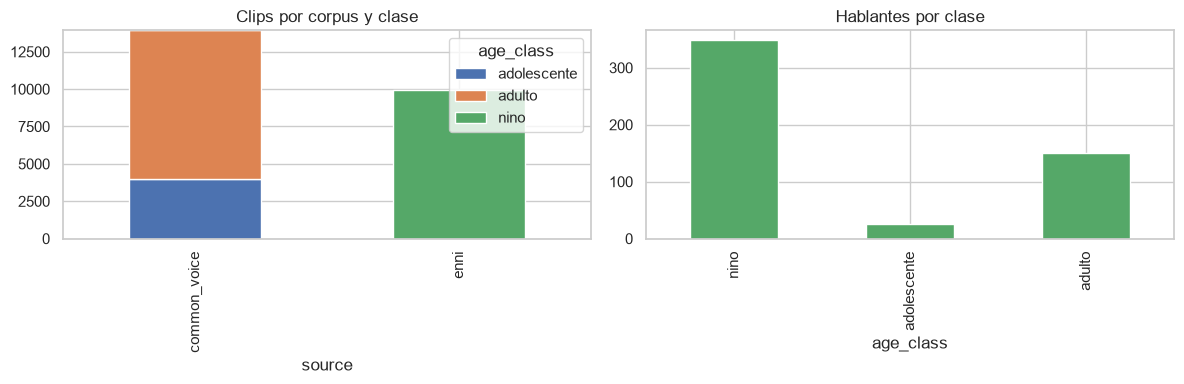

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.crosstab(df.source, df.age_class).plot.bar(stacked=True, ax=axes[0], title="Clips por corpus y clase")
df.groupby("age_class").speaker_id.nunique().reindex(CLASSES).plot.bar(ax=axes[1], title="Hablantes por clase", color="C2")
plt.tight_layout(); plt.show()

## 3. Partición por hablante

Un mismo hablante **nunca** aparece en dos particiones: si no, el modelo memorizaría voces y
las métricas serían irrealmente altas. La partición (~70 % train, ~15 % validación, ~15 % test,
repartiendo hablantes completos dentro de cada clase) viene hecha en `metadata.csv`; aquí solo se
verifica que no haya fuga.

In [3]:
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    inter = set(df[df.split == a].speaker_id) & set(df[df.split == b].speaker_id)
    assert not inter, f"Fuga de hablantes entre {a} y {b}"
display(pd.crosstab(df.split, df.age_class, margins=True))
pd.crosstab(df.split, df.age_class, values=df.speaker_id, aggfunc="nunique")

age_class,adolescente,adulto,nino,All
split,,,,
test,7,5,4,16
train,18,22,26,66
val,8,6,3,17
All,33,33,33,99


age_class,adolescente,adulto,nino
split,,,
test,3,5,3
train,8,20,26
val,4,5,3


## 4. Extracción de características

Se carga cada audio **una sola vez** y se pasa por los tres extractores:

- Se recorta a máximo 8 s, se normaliza el volumen y se quitan silencios.
- Clips < 1 s se descartan (no hay suficiente voz para estimar edad).
- Cada clip de **entrenamiento** recibe `AUG_COPIES` versiones aumentadas (10 efectos en
  `grooming_risk.audio.augment`: teléfono, ruidos, huecos, hum, eco, bitcrush, fondo).
  Se aumentan **todas las clases por igual** para que "audio ruidoso" no se convierta en una
  pista de clase. No se usa *pitch shift*: alteraría la señal de edad.

Las características se guardan en `datasets/features/` para no recalcularlas.

In [4]:
def cache_path(name):
    tag = f"_sub{SUBSAMPLE}" if SUBSAMPLE else ""
    return FEATURES_DIR / f"{name}{tag}.npz"

def extract_features(df, names):
    todo = [n for n in names if not cache_path(n).exists()]
    if todo:
        extractors = {n: build_extractor(n, DEVICE) for n in todo}
        dims, X, X_aug = {}, {n: [None] * len(df) for n in todo}, {n: [None] * len(df) for n in todo}
        aug_rng = np.random.default_rng(SEED)
        for i, row in enumerate(tqdm(df.itertuples(), total=len(df), desc="extrayendo")):
            try:
                wav = trim_silence(load_audio(row.path, max_sec=8.0))
            except Exception as exc:
                print("error", row.path, exc); continue
            if len(wav) < MIN_SEGMENT_SEC * SAMPLE_RATE:
                continue
            augs = [augment(wav, aug_rng) for _ in range(AUG_COPIES)] if row.split == "train" else []
            for n, ext in extractors.items():
                X[n][i] = ext.extract(wav)
                X_aug[n][i] = [ext.extract(a) for a in augs]
        for n in todo:
            d = next(v for v in X[n] if v is not None).shape[0]
            feats = np.stack([v if v is not None else np.full(d, np.nan, np.float32) for v in X[n]])
            aug = np.full((len(df), AUG_COPIES, d), np.nan, np.float32)
            for i, lst in enumerate(X_aug[n]):
                for k, v in enumerate(lst or []):
                    aug[i, k] = v
            np.savez_compressed(cache_path(n), X=feats, X_aug=aug, paths=df.path.to_numpy())
    out = {}
    for n in names:
        z = np.load(cache_path(n), allow_pickle=True)
        assert (z["paths"] == df.path.to_numpy()).all(), f"Caché {n} desalineada: bórrala y recalcula"
        out[n] = (z["X"], z["X_aug"])
    return out

FEATS = extract_features(df, EXTRACTORS)
valid = ~np.isnan(FEATS[EXTRACTORS[0]][0]).any(1)
print(f"clips válidos: {valid.sum()} / {len(df)}")
{n: X.shape for n, (X, _) in FEATS.items()}

hyperparams.yaml: 0.00B [00:00, ?B/s]

/Users/g0xk3r/Documents/GitHub/Antigrooming-MLaudio/.venv/lib/python3.13/site-packages/speechbrain/utils/autocast.py:188: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  wrapped_fwd = torch.cuda.amp.custom_fwd(fwd, cast_inputs=cast_inputs)


embedding_model.ckpt:   0%|          | 0.00/83.3M [00:00<?, ?B/s]

mean_var_norm_emb.ckpt:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

classifier.ckpt:   0%|          | 0.00/5.53M [00:00<?, ?B/s]

...

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

extrayendo:   0%|          | 0/99 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

clips válidos: 97 / 99


{'handcrafted': (99, 118), 'ecapa': (99, 192), 'wavlm': (99, 1536)}

**Validación exploratoria de la hipótesis acústica.** La primera característica handcrafted es
la media de log-F0. Si la hipótesis es correcta, los niños deberían tener el tono más alto.

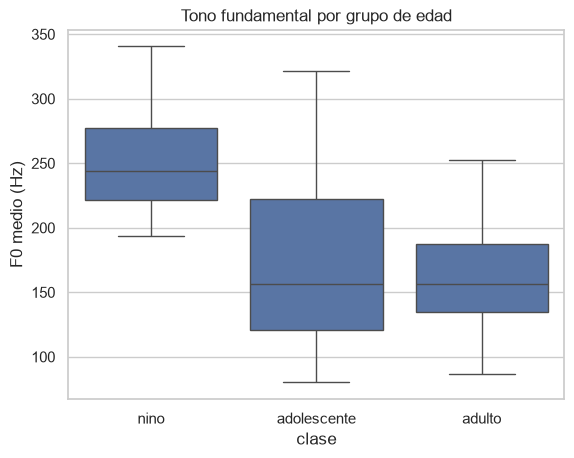

In [5]:
f0 = np.exp(FEATS["handcrafted"][0][:, 0])
plot_df = pd.DataFrame({"F0 medio (Hz)": f0, "clase": df.age_class})[valid]
sns.boxplot(data=plot_df, x="clase", y="F0 medio (Hz)", order=CLASSES, showfliers=False)
plt.title("Tono fundamental por grupo de edad"); plt.show()

In [ ]:
import shutil
import soundfile as sf

# Mismo nivel que common_voice/ y enni/ dentro de merged/audio/
DIRTY_DIR = MERGED_DIR / "audio" / "audios_sucios"

def exportar_audios_sucios(df, dest=DIRTY_DIR, rng=None):
    """Aplica augment() a cada clip de df y guarda WAV 16 kHz en audios_sucios/.
    Cada corrida borra la carpeta y la vuelve a crear: los filtros son aleatorios."""
    dest = Path(dest)
    if dest.exists():
        shutil.rmtree(dest)
    dest.mkdir(parents=True, exist_ok=True)
    rng = rng or np.random.default_rng(SEED)
    vistos, filas = {}, []
    for row in tqdm(df.itertuples(), total=len(df), desc="audios_sucios"):
        try:
            wav = trim_silence(load_audio(row.path, max_sec=8.0))
        except Exception as exc:
            print("error", row.path, exc)
            continue
        if len(wav) < MIN_SEGMENT_SEC * SAMPLE_RATE:
            continue
        sucio = augment(wav, rng)
        stem = f"{row.source}_{Path(row.path).stem}"
        vistos[stem] = vistos.get(stem, 0) + 1
        nombre = f"{stem}.wav" if vistos[stem] == 1 else f"{stem}_{vistos[stem]}.wav"
        out = dest / nombre
        sf.write(out, sucio, SAMPLE_RATE, subtype="PCM_16")
        filas.append({
            "path": nombre,
            "original_path": row.path,
            "speaker_id": row.speaker_id,
            "age": getattr(row, "age", None),
            "age_class": row.age_class,
            "source": row.source,
            "split": getattr(row, "split", None),
        })
    meta = pd.DataFrame(filas)
    meta.to_csv(dest / "metadata.csv", index=False)
    print(f"{len(meta)} WAV + metadata.csv → {dest}")
    return meta

# Catálogo completo: no uses `df` (ese está recortado por SUBSAMPLE=100).
# Así no tocas el subsample ni las tablas/conclusiones ya corridas.
_df_todos = pd.read_csv(MERGED_DIR / "metadata.csv")
_df_todos["path"] = _df_todos["path"].map(lambda p: str(MERGED_DIR / p))
print(f"exportando {len(_df_todos)} clips (SUBSAMPLE sigue en {SUBSAMPLE}, df no se toca)")
dirty = exportar_audios_sucios(_df_todos)
dirty.head()

exportando 23893 clips (SUBSAMPLE sigue en 100, df no se toca)


audios_sucios:   0%|          | 0/23893 [00:00<?, ?it/s]

In [8]:
import importlib
import grooming_risk.audio as _gaudio
importlib.reload(_gaudio)
from grooming_risk.audio import FILTROS, aplicar_filtro

import librosa
import librosa.display
from IPython.display import Audio, display
from grooming_risk.features import HandcraftedExtractor

_FORMANTS = HandcraftedExtractor._formants

def _hnr_aprox(wav, sr, f0):
    if not np.isfinite(f0) or f0 < 60:
        return np.nan
    spec = np.abs(np.fft.rfft(wav * np.hanning(len(wav))))
    freqs = np.fft.rfftfreq(len(wav), 1 / sr)
    harm = 0.0
    for k in range(1, 6):
        f = k * f0
        if f >= sr / 2:
            break
        band = (freqs > f - 25) & (freqs < f + 25)
        harm += float(spec[band].sum())
    tot = float(spec.sum()) + 1e-10
    return float(10 * np.log10(harm / (tot - harm + 1e-10)))

def describir(wav, sr=SAMPLE_RATE):
    hop, n_fft = 160, 512
    rms = librosa.feature.rms(y=wav, frame_length=n_fft, hop_length=hop)[0]
    zcr = librosa.feature.zero_crossing_rate(wav, frame_length=n_fft, hop_length=hop)[0]
    cen = librosa.feature.spectral_centroid(y=wav, sr=sr, n_fft=n_fft, hop_length=hop)[0]
    bw = librosa.feature.spectral_bandwidth(y=wav, sr=sr, n_fft=n_fft, hop_length=hop)[0]
    rol = librosa.feature.spectral_rolloff(y=wav, sr=sr, n_fft=n_fft, hop_length=hop)[0]
    f0 = librosa.yin(wav, fmin=60, fmax=600, sr=sr, frame_length=1024, hop_length=hop)
    voiced = rms > np.percentile(rms, 40)
    n = min(len(f0), len(voiced))
    f0_v = f0[:n][voiced[:n]]
    f0_v = f0_v[np.isfinite(f0_v)]
    f0_m = float(np.median(f0_v)) if f0_v.size else np.nan
    if f0_v.size > 2:
        per = 1.0 / np.clip(f0_v, 1e-3, None)
        jitter = float(np.mean(np.abs(np.diff(per))) / (np.mean(per) + 1e-10))
    else:
        jitter = np.nan
    shimmer = float(np.mean(np.abs(np.diff(rms))) / (np.mean(rms) + 1e-10)) if rms.size > 2 else np.nan
    frames = librosa.util.frame(np.pad(wav, (0, 400)), frame_length=400, hop_length=hop)
    nv = min(frames.shape[1], len(voiced))
    idx = np.where(voiced[:nv])[0][::3]
    formants = _FORMANTS(frames[:, idx], sr) if idx.size else np.full((1, 3), np.nan)
    f1, f2, f3 = np.nanmedian(formants, axis=0)
    return {
        "duracion_s": round(len(wav) / sr, 2),
        "RMS": round(float(np.sqrt(np.mean(wav ** 2))), 4),
        "ZCR": round(float(np.mean(zcr)), 3),
        "centroide": round(float(np.mean(cen)), 1),
        "bandwidth": round(float(np.mean(bw)), 1),
        "rolloff": round(float(np.mean(rol)), 1),
        "F0": round(f0_m, 1),
        "jitter": round(jitter, 4) if jitter == jitter else np.nan,
        "shimmer": round(shimmer, 4),
        "HNR": round(_hnr_aprox(wav, sr, f0_m), 2),
        "F1": round(float(f1), 1) if f1 == f1 else np.nan,
        "F2": round(float(f2), 1) if f2 == f2 else np.nan,
        "F3": round(float(f3), 1) if f3 == f3 else np.nan,
    }

def audio_de_clase(clase, seed=SEED):
    g = df[df.age_class == clase]
    if g.empty:
        raise ValueError(f"No hay clips de '{clase}' en df. Revisa SUBSAMPLE y la celda de Drive.")
    return g.sample(1, random_state=seed).iloc[0]

def experimento_clase(clase, seed=SEED):
    row = audio_de_clase(clase, seed)
    wav = trim_silence(load_audio(row.path, max_sec=8.0))
    print(f"{clase} · {row.source} · {Path(row.path).name} · {len(wav)/SAMPLE_RATE:.2f}s")
    display(Audio(wav, rate=SAMPLE_RATE))
    rng = np.random.default_rng(seed)
    filas = [{"filtro": "original", **describir(wav)}]
    variantes = {"original": wav}
    for nombre in FILTROS:
        sucio = aplicar_filtro(wav, nombre, rng)
        variantes[nombre] = sucio
        filas.append({"filtro": nombre, **describir(sucio)})
    tabla = pd.DataFrame(filas).set_index("filtro")
    display(tabla)
    claves = ["original", "telefono", "cama_musical", "ruido_blanco"]
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
    for ax, key in zip(axes, claves):
        mfcc = librosa.feature.mfcc(y=variantes[key], sr=SAMPLE_RATE, n_mfcc=13)
        librosa.display.specshow(mfcc, sr=SAMPLE_RATE, x_axis="time", ax=ax, cmap="magma")
        ax.set_title(key)
    plt.tight_layout(); plt.show()
    return tabla

print("Listo. Filtros:", ", ".join(FILTROS))
print("Clases en df:", df.age_class.value_counts().to_dict())

Listo. Filtros: telefono, ruido_blanco, saturacion, ruido_rosa, huecos, hum, clicks, eco, bitcrush, ambiente, cama_musical, sfx_juego
Clases en df: {'adulto': 33, 'nino': 33, 'adolescente': 33}


nino · enni · audio_004067.wav · 4.03s


,duracion_s,RMS,ZCR,centroide,bandwidth,rolloff,F0,jitter,shimmer,HNR,F1,F2,F3
filtro,,,,,,,,,,,,,
original,4.03,0.0651,0.163,1690.1,1412.7,2779.6,233.9,0.0220,0.1019,-5.16,629.6,1868.1,3366.2
telefono,4.03,0.0626,0.113,1048.6,670.3,1603.4,235.2,0.0315,0.1146,-4.50,612.5,1144.6,2530.6
ruido_blanco,4.03,0.0652,0.193,2251.1,1983.5,4283.6,234.3,0.0140,0.0995,-5.32,629.9,2150.6,3693.0
saturacion,4.03,0.2973,0.163,1701.9,1426.1,2833.2,233.7,0.0220,0.0943,-5.31,617.4,1827.2,3301.8
ruido_rosa,4.03,0.0655,0.142,1818.6,1823.1,3527.2,234.2,0.0139,0.0970,-5.35,632.4,2139.4,3606.0
huecos,4.03,0.0634,0.154,1602.3,1317.3,2620.7,233.7,0.0218,0.1038,-5.58,664.9,1884.1,3447.8
hum,4.03,0.0654,0.118,1474.3,1432.6,2560.8,234.3,0.0140,0.0970,-5.14,629.6,1868.4,3366.6
clicks,4.03,0.0651,0.163,1704.1,1425.8,2805.7,233.9,0.0220,0.1019,-5.18,629.6,1868.1,3366.2
eco,4.03,0.0686,0.108,1433.0,1442.6,2609.5,235.7,0.0215,0.0859,-4.96,632.5,1905.9,3529.3


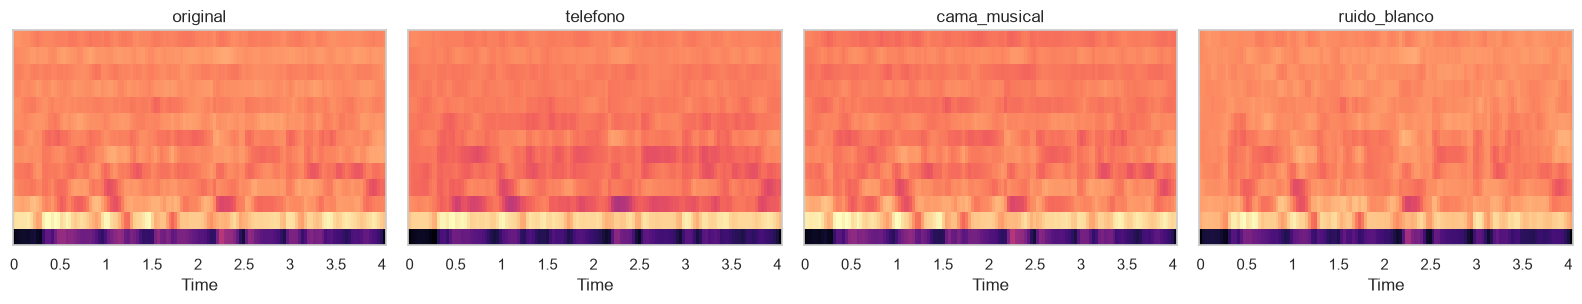

In [9]:
tabla_nino = experimento_clase("nino")

**Conclusión — `nino` (esta tabla: `enni/audio_004067.wav`, 4.03 s).**

Original: F0 **233.9 Hz**, F1/F2/F3 = **630 / 1868 / 3366**, centroide **1690 Hz**, ZCR **0.163**, jitter **0.022** (muy estable), HNR **−5.16**. Para ENNI, 234 Hz es un niño no tan agudo; igual queda por encima de un adulto típico.

Lo que **sí se rompió** en *este* clip:
- **teléfono:** el golpe más fuerte. Centroide 1690→**1048**, bandwidth 1413→**670**, rolloff 2780→**1603**, F2 1868→**1145**, F3 3366→**2531**. El F0 casi no se mueve (234→235). El niño no “envejece” por tono: se apaga el timbre y los formantes altos (tracto corto).
- **bitcrush:** ZCR 0.163→**0.055**, HNR −5.16→**−6.36**, F2 1868→**2261**. El códec inventa brillo y ensucia formantes.
- **ruido_blanco / rosa:** centroide hasta **2251 / 1819** y F3 hasta **3693 / 3606**. El LPC trata picos de ruido como formantes.
- **sfx_juego:** jitter 0.022→**0.054** (más del doble). Los hits de UI destrozan la periodicidad; el F0 medio sigue en 235.
- **saturación:** solo explota el RMS 0.065→**0.297**. Tono y formantes casi iguales.
- **clicks:** idéntico al original en esta corrida.

Lo que **no pasó** aquí: **cama_musical no bajó el F0** (233.9→234.2). El YIN se quedó en la laringe. El pad sí bajó centroide (1690→1419) y ZCR (0.163→0.114).

**Contrarrestar:** en este niño el riesgo es **formantes/timbre** (teléfono, bitcrush, ruido), no el tono. Entrenar con esos filtros; no usar un umbral de F0 solo. Si HNR baja y F2/F3 se desploman juntos, bajar confianza, no “subir de edad”.

adolescente · common_voice · cv-valid-train-sample-069055.wav · 5.34s


,duracion_s,RMS,ZCR,centroide,bandwidth,rolloff,F0,jitter,shimmer,HNR,F1,F2,F3
filtro,,,,,,,,,,,,,
original,5.34,0.0589,0.186,1863.6,1304.4,2994.9,142.5,0.1119,0.1748,-7.10,569.6,1649.0,2633.4
telefono,5.34,0.0579,0.125,1256.5,775.6,2068.5,146.0,0.1274,0.1854,-6.59,553.8,1477.0,2236.5
ruido_blanco,5.34,0.0593,0.271,2851.6,2175.1,5384.6,142.3,0.1122,0.1601,-7.76,828.2,2170.8,3747.1
saturacion,5.34,0.1965,0.186,1877.6,1331.4,3025.2,143.1,0.1131,0.1639,-7.10,580.1,1680.6,2668.3
ruido_rosa,5.34,0.0599,0.172,2134.9,1988.8,4218.3,143.4,0.1341,0.1561,-7.40,752.0,2048.6,3572.1
huecos,5.34,0.0588,0.177,1802.6,1266.2,2895.9,142.5,0.1118,0.1761,-7.04,577.3,1646.7,2628.8
hum,5.34,0.0591,0.156,1713.7,1344.1,2886.8,141.8,0.1430,0.1675,-7.15,578.2,1648.2,2636.6
clicks,5.34,0.0589,0.186,1901.2,1347.1,3090.6,143.1,0.1071,0.1750,-7.10,583.4,1718.1,2652.0
eco,5.34,0.0607,0.159,1749.3,1406.4,3063.4,146.3,0.1191,0.1602,-7.08,610.8,1697.9,2653.2


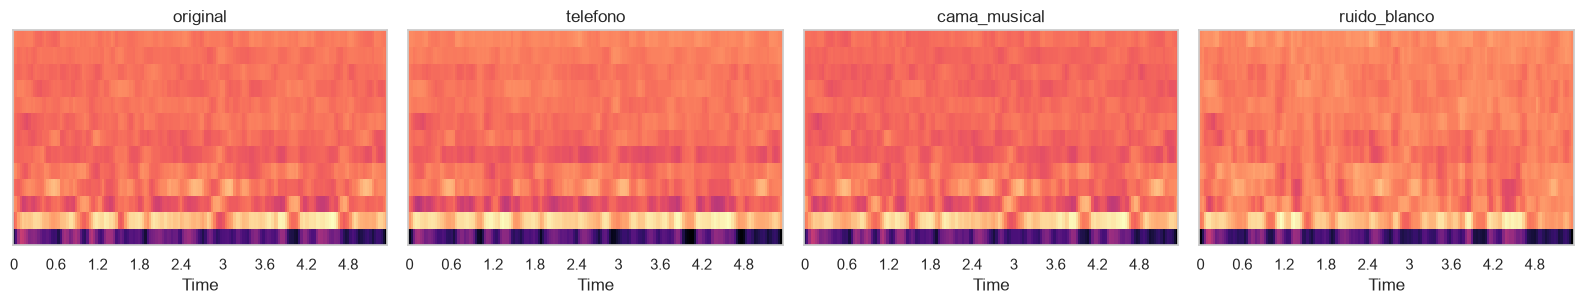

In [10]:
tabla_adolescente = experimento_clase("adolescente")

**Conclusión — `adolescente` (esta tabla: `common_voice/cv-valid-train-sample-069055.wav`, 5.34 s).**

Original: F0 **142.5 Hz**, F1/F2/F3 = **570 / 1649 / 2633**, centroide **1864 Hz**, ZCR **0.186**, jitter **0.112** (ya alto), HNR **−7.10**. **142 Hz es F0 de adulto**, no de teen. Esta fila confirma lo del README: `teens` de Common Voice es etiqueta ruidosa (incluye 18–19 y voces graves).

Lo que **sí se rompió** en *este* clip:
- **teléfono:** centroide 1864→**1257**, bandwidth 1304→**776**, rolloff 2995→**2069**, F3 2633→**2237**, F2 1649→**1477**. F0 142.5→**146.0**. Se apaga, no se vuelve niño.
- **ruido_blanco:** el peor para formantes. ZCR 0.186→**0.271**, centroide **2852**, F1 570→**828**, F2 **2171**, F3 **3747**. El LPC delinea ruido, no tracto. Un teen “parece” tener boca de niño por artefactos.
- **ruido_rosa:** misma historia más suave: F1 **752**, F2 **2049**, F3 **3572**, jitter 0.112→**0.134**.
- **bitcrush:** ZCR 0.186→**0.037**, HNR −7.10→**−7.95**, F1 **873**, F2 **2335**. Códec de chat: formantes inventados + menos cruces (se “cuadran” las muestras).
- **hum:** jitter 0.112→**0.143** (el más alto). El 50/60 Hz le pelea al F0 de 142 Hz, que está cerca del 2º armónico de 60 Hz.
- **saturación:** RMS 0.059→**0.197**; el resto casi igual.
- **cama_musical:** F0 142.5→**143.4** (no se lo llevó). Centroide 1864→**1665**.

**Contrarrestar:** este “adolescente” ya nació con cara acústica de adulto. El modelo no puede arreglar la etiqueta. En juego, ruido/bitcrush son el riesgo (formantes falsos → menor). Si F1 salta de 570 a 800+ y el HNR baja, no creer la clase: es ruido, no pubertad al revés.

adulto · common_voice · cv-valid-train-sample-022232.wav · 3.81s


,duracion_s,RMS,ZCR,centroide,bandwidth,rolloff,F0,jitter,shimmer,HNR,F1,F2,F3
filtro,,,,,,,,,,,,,
original,3.81,0.0517,0.102,1593.9,1792.1,3473.0,149.7,0.1485,0.1122,-5.08,636.3,2229.8,3544.9
telefono,3.81,0.0342,0.109,1108.5,826.2,2042.4,150.8,0.2115,0.1233,-5.71,544.4,1390.1,2241.2
ruido_blanco,3.81,0.0525,0.312,3067.1,2310.9,5849.0,149.6,0.1388,0.0973,-6.07,919.1,2511.2,3867.0
saturacion,3.81,0.2092,0.102,1601.3,1797.1,3509.8,149.7,0.1485,0.1026,-5.22,643.3,2084.3,3412.9
ruido_rosa,3.81,0.0518,0.117,1747.1,1905.4,3773.0,151.1,0.1646,0.1110,-5.25,640.2,2193.7,3604.5
huecos,3.81,0.0470,0.100,1573.5,1757.9,3450.5,155.2,0.1666,0.1381,-6.56,627.9,2098.7,3526.2
hum,3.81,0.0519,0.093,1458.7,1759.5,3227.3,145.8,0.0561,0.1112,-5.24,644.0,2216.6,3529.0
clicks,3.81,0.0518,0.102,1612.8,1799.0,3505.0,149.7,0.1610,0.1125,-5.12,636.3,2256.1,3544.9
eco,3.81,0.0541,0.100,1592.8,1815.3,3541.4,149.5,0.1476,0.0977,-5.06,552.0,1895.8,3464.1


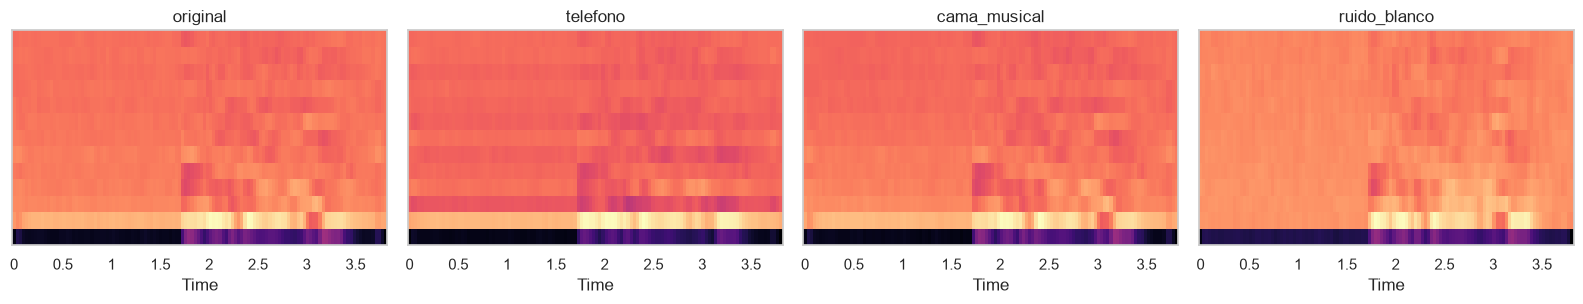

In [11]:
tabla_adulto = experimento_clase("adulto")

**Conclusión — `adulto` (esta tabla: `common_voice/cv-valid-train-sample-022232.wav`, 3.81 s).**

Original: F0 **149.7 Hz**, F1/F2/F3 = **636 / 2230 / 3545**, centroide **1594 Hz**, ZCR **0.102**, jitter **0.1485** (ya inestable), HNR **−5.08**, RMS **0.0517**. 150 Hz es adulto agudo / femenino; no es un barítono de 110 Hz.

Lo que **sí se rompió** en *este* clip (aquí sí hay rejuvenecimiento):
- **cama_musical:** el único caso de las 3 tablas donde el BGM **se lleva el F0**: 149.7→**170.8 Hz**. F1 636→**464**, jitter 0.1485→**0.1744**, centroide 1594→**1328**. El pad no solo “ensucia”: empuja el tono hacia teen y tuerce el primer formante. En juego esto es el falso positivo de menor.
- **ambiente:** F0 149.7→**157.1**, ZCR 0.102→**0.078**, centroide **1315**. F1 se queda en **652** (casi igual). El rumble apaga brillo y sube un poco el tono; no inventa un tracto de niño.
- **eco:** F1 636→**552**, F2 2230→**1896**. Ahí sí se mueven formantes, sin tocar el F0 (149.5).
- **huecos:** F0 **155.2**, HNR −5.08→**−6.56**, jitter **0.1666**, shimmer **0.1381**. Al recortar, el tono se pone nervioso; F3 casi no cambia (3545→3526).
- **teléfono:** RMS 0.0517→**0.0342**, centroide 1594→**1109**, F2 2230→**1390**, F3 3545→**2241**, jitter 0.1485→**0.2115**. Se apaga y pierde formantes altos. El F0 **no baja**: 149.7→**150.8**.
- **ruido_blanco:** ZCR 0.102→**0.312** (el salto más grande de las 3 tablas), centroide **3067**, F1 **919**, F3 **3867**. El adulto “parece” más brillante / más niño por el ruido, no por la laringe.
- **hum:** F0 149.7→**145.8**, jitter **0.0561** (aquí el 50/60 Hz *estabilizó* el tono; no lo rompió).
- **saturación:** RMS 0.0517→**0.2092**; F0 idéntico (149.7).
- **sfx_juego:** jitter 0.1485→**0.1702**; F0 se queda en 150.3.

**Contrarrestar:** este adulto es el caso inverso al niño: **la cama musical sí lo rejuveneció**. Entrenar con BGM; si F0 sube ~20 Hz y F1 cae a la vez que hay pad, no creer “adolescente”. Priorizar embedding (ECAPA) cuando HNR es malo. Recuerda: el score alto solo dice “parece menor + adulto”, no grooming.

## 5. Modelos y justificación

Se entrenan **tres familias complementarias**, de lo más interpretable a lo más potente,
para poder justificar con datos cuál desplegar:

| Modelo | Representación | Clasificador | Por qué |
|---|---|---|---|
| **A. Acústico clásico** | ~130 rasgos: F0, formantes F1–F3, MFCC+Δ, espectrales | Gradient Boosting (`HistGradientBoosting`) | La fisiología explica la edad: los niños tienen cuerdas vocales y tracto vocal más cortos → F0 y formantes más altos. Los árboles capturan umbrales no lineales (p.ej. F0 alto + F1 alto) y son interpretables. Línea base barata que corre en cualquier CPU. |
| **B. ECAPA-TDNN + SVM** | Embedding de hablante de 192 dims (SpeechBrain, VoxCeleb) | SVM con kernel RBF | ECAPA es el estado del arte en reconocimiento de hablante; su embedding resume la "huella vocal", que incluye edad y sexo. Es compacto, así que un SVM con pocos datos de menores generaliza bien (margen máximo). Además se reutiliza para la diarización. |
| **C. WavLM + regresión logística** | Capas 3–8 de WavLM-base-plus, pooling media+desv. (1536 dims) | Regresión logística (*linear probe*) | Modelo autosupervisado entrenado con 94 k h; líder del benchmark SUPERB en tareas de hablante y paralingüística. Sus capas intermedias codifican edad/sexo. Un clasificador lineal sobre representaciones congeladas es eficiente en datos y evita sobreajustar con pocos menores (no hacemos *fine-tuning* completo por el tamaño del dataset y para entrenar en local). |
| *A2. Acústico + Random Forest* | Los mismos ~118 rasgos de A | Random Forest | Línea base **liviana** clásica: sin redes neuronales, corre en cualquier CPU y sus importancias son fáciles de explicar. ¿El *boosting* de A aporta frente a un ensamble de árboles independiente? |
| *A3. Acústico + regresión logística* | Los mismos rasgos de A | Regresión logística | El **piso**: ¿cuánto rinde un modelo lineal sobre rasgos fisiológicos? |
| *B2. ECAPA + Random Forest* | El mismo embedding de B | Random Forest | Aísla el efecto del **clasificador**: misma representación que B con otro modelo. |
| *D. Referencia audEERING* | wav2vec2-large afinado para edad | — (zero-shot) | Modelo publicado de estimación de edad. Sirve de cota externa: ¿nuestros modelos superan a uno ya existente? Licencia no comercial → no se despliega. |

Con A/A2/A3 (misma representación) y B/B2 (mismo embedding) la comparación se lee en dos ejes:
qué aporta la **representación** y qué aporta el **clasificador**.

**Decisiones comunes**
- `class_weight="balanced"`: hay muchos menos menores que adultos.
- Hiperparámetros elegidos en **validación** con F1-macro.
- **Calibración sigmoide** sobre validación: el puntaje de riesgo multiplica probabilidades, así que
  estas deben ser fiables (un 0.9 debe significar ~90 % de aciertos), no solo bien ordenadas.

In [7]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

y = df.age_class.to_numpy()
idx = {s: np.where((df.split == s).to_numpy() & valid)[0] for s in ["train", "val", "test"]}

def get_xy(name, split, with_aug=False):
    X, X_aug = FEATS[name]
    i = idx[split]
    Xs, ys = [X[i]], [y[i]]
    if with_aug:
        for k in range(X_aug.shape[1]):
            ok = ~np.isnan(X_aug[i, k]).any(1)
            Xs.append(X_aug[i, k][ok]); ys.append(y[i][ok])
    return np.vstack(Xs), np.concatenate(ys)

MODELS = {
    "A_handcrafted_gbm": ("handcrafted",
        HistGradientBoostingClassifier(max_iter=400, class_weight="balanced", early_stopping=True,
                                       random_state=SEED),
        {"learning_rate": [0.05, 0.1], "max_depth": [None, 6], "l2_regularization": [0.0, 1.0]}),
    "B_ecapa_svm": ("ecapa",
        make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
        {"svc__C": [0.3, 1, 3, 10], "svc__gamma": ["scale"]}),
    "C_wavlm_logreg": ("wavlm",
        make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)),
        {"logisticregression__C": [0.001, 0.01, 0.1, 1.0]}),
    # Modelos livianos de comparación
    "A2_handcrafted_rf": ("handcrafted",
        RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1,
                               random_state=SEED),
        {"max_depth": [12, 24], "min_samples_leaf": [2, 8]}),
    "A3_handcrafted_logreg": ("handcrafted",
        make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)),
        {"logisticregression__C": [0.01, 0.1, 1.0, 10.0]}),
    "B2_ecapa_rf": ("ecapa",
        RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1,
                               random_state=SEED),
        {"max_depth": [12, 24], "min_samples_leaf": [2, 8]}),
}
MODELS = {k: v for k, v in MODELS.items() if v[0] in EXTRACTORS}

def calibrate(model, X, y):
    try:
        from sklearn.frozen import FrozenEstimator   # scikit-learn >= 1.6
        cal = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid")
    except ImportError:
        cal = CalibratedClassifierCV(model, method="sigmoid", cv="prefit")
    return cal.fit(X, y)

def metrics(y_true, proba):
    y_pred = np.array(CLASSES)[proba.argmax(1)]
    rep = classification_report(y_true, y_pred, labels=CLASSES, output_dict=True, zero_division=0)
    minor = y_true != "adulto"
    p_minor = 1 - proba[:, CLASSES.index("adulto")]
    return {
        "f1_macro": f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        **{f"recall_{c}": rep[c]["recall"] for c in CLASSES},
        "auc_menor_vs_adulto": roc_auc_score(minor, p_minor) if 0 < minor.mean() < 1 else np.nan,
    }

In [8]:
trained, val_scores = {}, {}
for name, (feat, base, grid) in MODELS.items():
    Xtr, ytr = get_xy(feat, "train", with_aug=True)
    Xva, yva = get_xy(feat, "val")
    best = (-1, None, None)
    for params in tqdm(list(ParameterGrid(grid)), desc=name):
        m = clone(base).set_params(**params).fit(Xtr, ytr)
        score = f1_score(yva, m.predict(Xva), average="macro")
        if score > best[0]:
            best = (score, params, m)
    print(f"{name}: mejor F1-macro val = {best[0]:.3f} con {best[1]}")
    trained[name] = {"feat": feat, "model": calibrate(best[2], Xva, yva), "params": best[1]}
    val_scores[name] = best[0]

A_handcrafted_gbm:   0%|          | 0/8 [00:00<?, ?it/s]

A_handcrafted_gbm: mejor F1-macro val = 0.706 con {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_depth': 6}


B_ecapa_svm:   0%|          | 0/4 [00:00<?, ?it/s]

B_ecapa_svm: mejor F1-macro val = 0.745 con {'svc__C': 0.3, 'svc__gamma': 'scale'}


C_wavlm_logreg:   0%|          | 0/4 [00:00<?, ?it/s]

...

A2_handcrafted_rf: mejor F1-macro val = 0.710 con {'max_depth': 12, 'min_samples_leaf': 8}


A3_handcrafted_logreg:   0%|          | 0/4 [00:00<?, ?it/s]

A3_handcrafted_logreg: mejor F1-macro val = 0.711 con {'logisticregression__C': 0.01}


B2_ecapa_rf:   0%|          | 0/4 [00:00<?, ?it/s]

B2_ecapa_rf: mejor F1-macro val = 0.660 con {'max_depth': 12, 'min_samples_leaf': 8}


## 6. Evaluación en test

Métricas:
- **F1-macro** y **balanced accuracy**: tratan a las tres clases por igual pese al desbalance.
- **Recall de `nino`**: el error más grave para una alerta es no detectar al menor (falso negativo).
- **AUC menor-vs-adulto**: calidad de la probabilidad `P(menor)` que alimenta el riesgo.

Se reporta a nivel de **clip** y a nivel de **hablante** (promediando las probabilidades de todos
sus clips, que es como funciona la API con un hablante diarizado).

Ojo con el nivel *hablante* en este dataset: en Common Voice cada "hablante" es un grupo
demográfico con muchas personas, y en test solo hay 4 grupos de adolescentes, así que esa
métrica es muy ruidosa. Por eso la selección usa el nivel **clip**.

In [9]:
results, test_probas = [], {}
test_df_valid = df.iloc[idx["test"]]
for name, t in trained.items():
    Xte, yte = get_xy(t["feat"], "test")
    proba = reorder_proba(t["model"].predict_proba(Xte), t["model"].classes_)
    test_probas[name] = proba
    spk = (pd.DataFrame(proba, columns=CLASSES).assign(spk=test_df_valid.speaker_id.values, y=yte)
             .groupby("spk").agg({**{c: "mean" for c in CLASSES}, "y": "first"}))
    results.append({"modelo": name, "nivel": "clip", **metrics(yte, proba)})
    results.append({"modelo": name, "nivel": "hablante", **metrics(spk.y.to_numpy(), spk[CLASSES].to_numpy())})

if RUN_AUDEERING_REFERENCE:
    from grooming_risk.features import AudeeringAgeModel
    ref = AudeeringAgeModel(DEVICE)
    proba = np.stack([ref.predict_proba(trim_silence(load_audio(p, max_sec=8.0)))
                      for p in tqdm(test_df_valid.path, desc="audeering")])
    test_probas["D_audeering_zero_shot"] = proba
    results.append({"modelo": "D_audeering_zero_shot", "nivel": "clip", **metrics(test_df_valid.age_class.to_numpy(), proba)})

res = pd.DataFrame(results).set_index(["modelo", "nivel"]).round(3)
res

f1_macro  balanced_acc  recall_nino  \
modelo                nivel                                           
A_handcrafted_gbm     clip         0.708         0.710        0.997   
                      hablante     0.634         0.653        1.000   
B_ecapa_svm           clip         0.817         0.814        0.987   
                      hablante     0.837         0.819        1.000   
C_wavlm_logreg        clip         0.786         0.778        1.000   
                      hablante     0.837         0.819        1.000   
A2_handcrafted_rf     clip         0.730         0.728        0.994   
                      hablante     0.624         0.639        1.000   
A3_handcrafted_logreg clip         0.598         0.658        0.999   
                      hablante     0.631         0.653        1.000   
B2_ecapa_rf           clip         0.776         0.768        0.965   
                      hablante     0.841         0.827        0.981   

                                recall_adolescente  recall_adulto  \
modelo                nivel                                         
A_handcrafted_gbm     clip                   0.261          0.872   
                      hablante               0.000          0.958   
B_ecapa_svm           clip                   0.604          0.852   
                      hablante               0.500          0.958   
C_wavlm_logreg        clip                   0.427          0.906   
                      hablante               0.500          0.958   
A2_handcrafted_rf     clip                   0.308          0.884   
                      hablante               0.000          0.917   
A3_handcrafted_logreg clip                   0.010          0.965   
                      hablante               0.000          0.958   
B2_ecapa_rf           clip                   0.430          0.910   
                      hablante               0.500          1.000   

                                auc_menor_vs_adulto  
modelo                nivel                          
A_handcrafted_gbm     clip                    0.870  
                      hablante                0.986  
B_ecapa_svm           clip                    0.943  
                      hablante                0.998  
C_wavlm_logreg        clip                    0.940  
                      hablante                0.993  
A2_handcrafted_rf     clip                    0.900  
                      hablante                0.994  
A3_handcrafted_logreg clip                    0.872  
                      hablante                0.988  
B2_ecapa_rf           clip                    0.941  
                      hablante                0.999

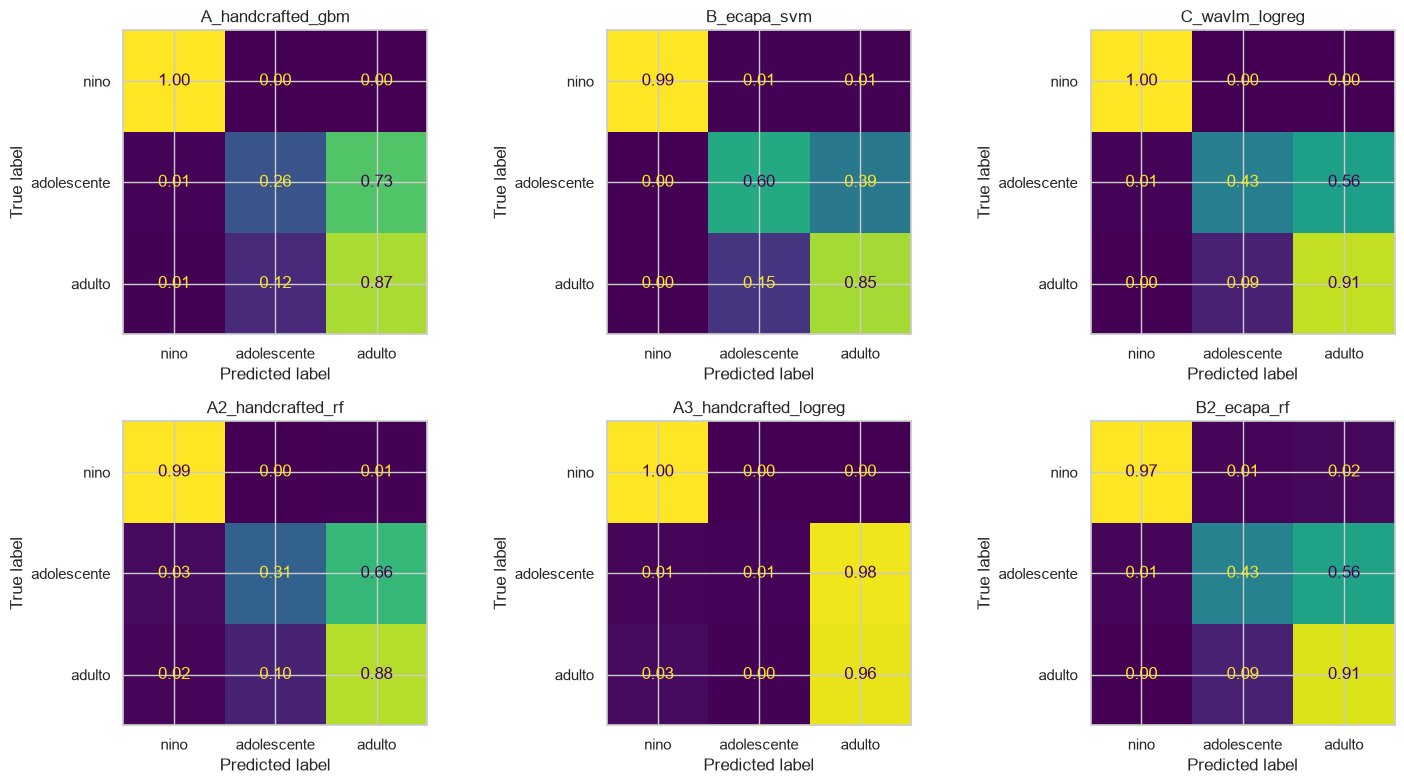

In [10]:
ncols = 3
nrows = -(-len(test_probas) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
yte = test_df_valid.age_class.to_numpy()
for ax, (name, proba) in zip(np.atleast_1d(axes).ravel(), test_probas.items()):
    ConfusionMatrixDisplay.from_predictions(yte, np.array(CLASSES)[proba.argmax(1)], labels=CLASSES,
                                            normalize="true", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(name)
for ax in np.atleast_1d(axes).ravel()[len(test_probas):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Eficiencia

Para justificar un modelo "liviano" hacen falta números: tiempo de inferencia por clip (extractor +
clasificador, en CPU, sobre 50 clips de test) y tamaño en disco del clasificador y de los pesos del
extractor.

In [11]:
import io, time, joblib

def weights_mb(ext):
    model = getattr(ext, "model", None)
    if model is None:            # handcrafted: sin red neuronal
        return 0.0
    module = model.mods.embedding_model if hasattr(model, "mods") else model
    return sum(p.numel() for p in module.parameters()) * 4 / 1e6   # float32

bench = [trim_silence(load_audio(p, max_sec=8.0)) for p in test_df_valid.path.sample(50, random_state=SEED)]
ext_cost = {}
for feat in sorted({t["feat"] for t in trained.values()}):
    ext = build_extractor(feat, DEVICE)
    ext.extract(bench[0])        # calentamiento
    t0 = time.perf_counter()
    for w in bench:
        ext.extract(w)
    ext_cost[feat] = (1000 * (time.perf_counter() - t0) / len(bench), weights_mb(ext))

eff = []
for name, t in trained.items():
    Xte, _ = get_xy(t["feat"], "test")
    t0 = time.perf_counter()
    t["model"].predict_proba(Xte)
    ms_clf = 1000 * (time.perf_counter() - t0) / len(Xte)
    buf = io.BytesIO()
    joblib.dump(t["model"], buf)
    ms_ext, mb_ext = ext_cost[t["feat"]]
    eff.append({"modelo": name, "f1_macro_clip": res.loc[(name, "clip"), "f1_macro"],
                "ms_extractor": ms_ext, "ms_clasificador": ms_clf, "ms_total": ms_ext + ms_clf,
                "MB_clasificador": buf.tell() / 1e6, "MB_pesos_extractor": mb_ext})
eff = pd.DataFrame(eff).set_index("modelo").sort_values("f1_macro_clip", ascending=False)
eff.round(3)

/Users/davidcervantes/Documents/Reconocimiento de Voz/riesgo-grooming-audio/.venv/lib/python3.12/site-packages/speechbrain/utils/autocast.py:188: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  wrapped_fwd = torch.cuda.amp.custom_fwd(fwd, cast_inputs=cast_inputs)


,f1_macro_clip,ms_extractor,ms_clasificador,ms_total,MB_clasificador,MB_pesos_extractor
modelo,,,,,,
B_ecapa_svm,0.817,28.622,0.826,29.448,15.895,83.070
C_wavlm_logreg,0.786,88.991,0.002,88.993,0.058,377.528
B2_ecapa_rf,0.776,28.622,0.011,28.633,37.730,83.070
A2_handcrafted_rf,0.730,16.477,0.011,16.488,35.940,0.000
A_handcrafted_gbm,0.708,16.477,0.008,16.485,2.024,0.000
A3_handcrafted_logreg,0.598,16.477,0.000,16.477,0.007,0.000


### Selección del mejor modelo

Criterio: mayor **F1-macro a nivel de clip** en test; en caso de empate (±0.01) gana el de mayor
**recall de `nino`**. (Con hablantes reales y suficientes por clase convendría usar el nivel
hablante, que es la unidad de la API; aquí los pseudo-hablantes de Common Voice lo hacen poco
fiable.) La referencia de audEERING no es elegible (licencia no comercial y no fue entrenada por
nosotros).

In [12]:
cand = res.xs("clip", level="nivel").loc[list(trained)]
top = cand.f1_macro.max()
BEST = cand[cand.f1_macro >= top - 0.01].sort_values("recall_nino", ascending=False).index[0]
print("Mejor modelo:", BEST)
cand.sort_values("f1_macro", ascending=False)

Mejor modelo: B_ecapa_svm


,f1_macro,balanced_acc,recall_nino,recall_adolescente,recall_adulto,auc_menor_vs_adulto
modelo,,,,,,
B_ecapa_svm,0.817,0.814,0.987,0.604,0.852,0.943
C_wavlm_logreg,0.786,0.778,1.000,0.427,0.906,0.940
B2_ecapa_rf,0.776,0.768,0.965,0.430,0.910,0.941
A2_handcrafted_rf,0.730,0.728,0.994,0.308,0.884,0.900
A_handcrafted_gbm,0.708,0.710,0.997,0.261,0.872,0.870
A3_handcrafted_logreg,0.598,0.658,0.999,0.010,0.965,0.872


## 7. Auditoría de sesgo por canal

En este dataset clase y corpus están confundidos (`nino` = ENNI), así que la prueba clásica de
"¿se puede predecir el corpus?" equivale a predecir `nino` y no aporta información. Se hacen tres
comprobaciones:

1. **Rendimiento por corpus**: recall de cada clase dentro de cada corpus.
2. **Predictibilidad del corpus** (se mantiene como referencia: aquí siempre saldrá alta).
3. **Robustez al canal**: se degrada el audio de test con la misma aumentación de canal del
   entrenamiento (teléfono, ruido, saturación). Si el modelo usara "audio limpio = niño", el recall
   de `nino` caería mucho al ensuciar los clips de ENNI.

In [13]:
proba = test_probas[BEST]
by_src = []
for src, g in test_df_valid.assign(pred=np.array(CLASSES)[proba.argmax(1)]).groupby("source"):
    row = {"corpus": src, "n": len(g), "accuracy": (g.pred == g.age_class).mean()}
    row.update({f"recall_{c}": (g[g.age_class == c].pred == c).mean() if (g.age_class == c).any() else np.nan
                for c in CLASSES})
    by_src.append(row)
display(pd.DataFrame(by_src).round(3))

from sklearn.model_selection import cross_val_score, GroupKFold
if df.source[valid].nunique() > 1:
    feat = trained[BEST]["feat"]
    X_all = FEATS[feat][0][valid]
    src_acc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                              X_all, df.source[valid], groups=df.speaker_id[valid], cv=GroupKFold(5)).mean()
    print(f"Exactitud prediciendo el corpus con features '{feat}': {src_acc:.3f} "
          f"(azar ≈ {df.source[valid].value_counts(normalize=True).max():.3f})")
else:
    print("Solo hay un corpus: no aplica la prueba de predictibilidad del corpus.")

# 3. Robustez al canal: mismo test con audio degradado
ext = build_extractor(trained[BEST]["feat"], DEVICE)
deg_rng = np.random.default_rng(SEED)
X_deg = np.stack([ext.extract(augment(trim_silence(load_audio(p, max_sec=8.0)), deg_rng))
                  for p in tqdm(test_df_valid.path, desc="test degradado")])
proba_deg = reorder_proba(trained[BEST]["model"].predict_proba(X_deg), trained[BEST]["model"].classes_)
robustez = pd.DataFrame([{"audio": "original", **metrics(yte, proba)},
                         {"audio": "degradado", **metrics(yte, proba_deg)}]).set_index("audio")
robustez.round(3)

,corpus,n,accuracy,recall_nino,recall_adolescente,recall_adulto
0,common_voice,2217,0.773,NaN,0.604,0.852
1,enni,1507,0.987,0.987,NaN,NaN


Exactitud prediciendo el corpus con features 'ecapa': 0.988 (azar ≈ 0.579)


test degradado:   0%|          | 0/3724 [00:00<?, ?it/s]

,f1_macro,balanced_acc,recall_nino,recall_adolescente,recall_adulto,auc_menor_vs_adulto
audio,,,,,,
original,0.817,0.814,0.987,0.604,0.852,0.943
degradado,0.813,0.807,0.979,0.567,0.876,0.944


## 8. Guardado del mejor modelo

Se guarda un *bundle* `models/best_model.joblib` con el clasificador calibrado y el nombre del
extractor que necesita, más `models/model_card.json` con las métricas. La API y Docker leen
este bundle, así que **siempre despliegan el modelo ganador** sin cambiar código.

In [14]:
best = trained[BEST]
card_metrics = res.loc[BEST].to_dict(orient="index")
path = save_bundle(best["model"], best["feat"], card_metrics, MODELS_DIR, extra={
    "model_name": BEST,
    "hyperparameters": best["params"],
    "dataset": "datasets/merged (ver construccion_dataset.ipynb)",
    "train_sources": sorted(df.source.unique()),
    "n_train_clips": int(len(idx["train"])),
    "n_speakers": int(df.speaker_id.nunique()),
    "comparison_test_clip": cand.round(3).to_dict(orient="index"),
    "efficiency_cpu": eff.round(3).to_dict(orient="index"),
    "limitations": [
        "nino solo de habla sintetizada (ENNI); adolescente/adulto solo de Common Voice: clase y canal confundidos",
        "Common Voice teens = < 19 anos (etiqueta ruidosa)",
        "Common Voice sin client_id: pseudo-hablantes por (decada, genero, acento)",
        "Solo ingles",
    ],
})
print("Guardado en", path)
print((MODELS_DIR / "model_card.json").read_text()[:1500])

Guardado en /Users/davidcervantes/Documents/Reconocimiento de Voz/riesgo-grooming-audio/models/best_model.joblib
{
  "extractor": "ecapa",
  "classes": [
    "nino",
    "adolescente",
    "adulto"
  ],
  "metrics": {
    "clip": {
      "f1_macro": 0.817,
      "balanced_acc": 0.814,
      "recall_nino": 0.987,
      "recall_adolescente": 0.604,
      "recall_adulto": 0.852,
      "auc_menor_vs_adulto": 0.943
    },
    "hablante": {
      "f1_macro": 0.837,
      "balanced_acc": 0.819,
      "recall_nino": 1.0,
      "recall_adolescente": 0.5,
      "recall_adulto": 0.958,
      "auc_menor_vs_adulto": 0.998
    }
  },
  "model_name": "B_ecapa_svm",
  "hyperparameters": {
    "svc__C": 0.3,
    "svc__gamma": "scale"
  },
  "dataset": "datasets/merged (ver construccion_dataset.ipynb)",
  "train_sources": [
    "common_voice",
    "enni"
  ],
  "n_train_clips": 16078,
  "n_speakers": 524,
  "comparison_test_clip": {
    "A_handcrafted_gbm": {
      "f1_macro": 0.708,
      "balanced_acc

## 9. Prueba de punta a punta: conversaciones simuladas

Se construyen conversaciones artificiales con hablantes de **test** (nunca vistos) alternando sus
turnos, y se pasan por el pipeline completo (diarización → edad → riesgo), igual que la API.

Limitación: los dos hablantes suelen venir de grabaciones distintas, lo que facilita la diarización
respecto a una llamada real. Estos números son optimistas para la diarización.

Como un pseudo-hablante de Common Voice agrupa a varias personas, de cada uno se usa **un solo
clip** (una sola persona); los niños de ENNI sí aportan varios turnos del mismo hablante.

In [15]:
analyzer = GroomingRiskAnalyzer(MODELS_DIR, device=DEVICE)
test_pool = test_df_valid.groupby(["age_class", "speaker_id"]).path.apply(list)

def make_conversation(classes, rng, turns=3, pause=0.4):
    speakers = []
    for c in classes:
        options = [s for s in test_pool.loc[c].index if s not in speakers]
        speakers.append(options[rng.integers(len(options))])
    # pseudo-hablante de Common Voice = varias personas → un solo clip
    clips = {s: [trim_silence(load_audio(p, max_sec=6.0))
                 for p in test_pool.loc[(c, s)][:1 if s.startswith("cv:") else turns]]
             for c, s in zip(classes, speakers)}
    silence = np.zeros(int(pause * SAMPLE_RATE), np.float32)
    parts = []
    for t in range(turns):
        for s in speakers:
            if t < len(clips[s]):
                parts += [clips[s][t], silence]
    return np.concatenate(parts)

SCENARIOS = {"nino + adulto": ["nino", "adulto"], "adolescente + adulto": ["adolescente", "adulto"],
             "adulto + adulto": ["adulto", "adulto"], "nino + nino": ["nino", "nino"],
             "adulto solo": ["adulto"]}
N_CONV = 20
sim = []
for scen, classes in SCENARIOS.items():
    available = pd.Series(test_pool.index.get_level_values(0)).value_counts()
    if any(available.get(c, 0) < classes.count(c) for c in set(classes)):
        print("sin hablantes suficientes para", scen); continue
    for _ in tqdm(range(N_CONV), desc=scen):
        out = analyzer.analyze(make_conversation(classes, rng))
        sim.append({"escenario": scen, "riesgo": out["risk_score"], "nivel": out["risk_level"],
                    "hablantes_detectados": out["num_speakers"]})
sim = pd.DataFrame(sim)
summary = sim.groupby("escenario").agg(riesgo_medio=("riesgo", "mean"),
                                       pct_alerta_alta=("nivel", lambda s: (s == "alto").mean()),
                                       hablantes_detectados=("hablantes_detectados", "mean"))
summary.round(3)

nino + adulto:   0%|          | 0/20 [00:00<?, ?it/s]

adolescente + adulto:   0%|          | 0/20 [00:00<?, ?it/s]

adulto + adulto:   0%|          | 0/20 [00:00<?, ?it/s]

nino + nino:   0%|          | 0/20 [00:00<?, ?it/s]

adulto solo:   0%|          | 0/20 [00:00<?, ?it/s]

,riesgo_medio,pct_alerta_alta,hablantes_detectados
escenario,,,
adolescente + adulto,0.231,0.0,2.05
adulto + adulto,0.183,0.0,2.40
adulto solo,0.068,0.0,1.15
nino + adulto,0.585,0.8,3.30
nino + nino,0.084,0.0,3.85


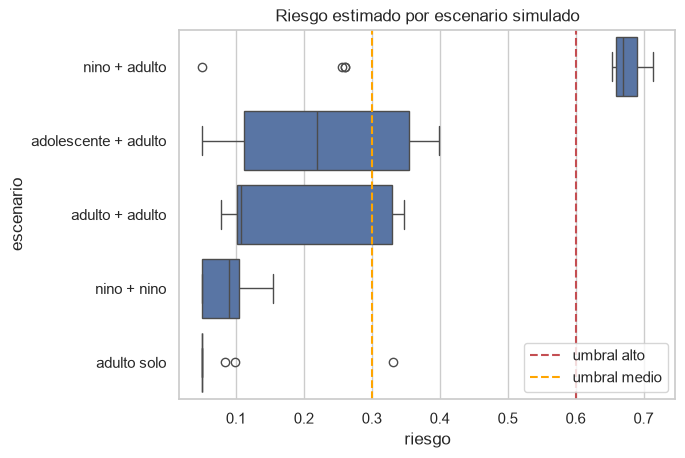

In [16]:
sns.boxplot(data=sim, x="riesgo", y="escenario", order=list(SCENARIOS))
plt.axvline(0.6, ls="--", c="r", label="umbral alto"); plt.axvline(0.3, ls="--", c="orange", label="umbral medio")
plt.legend(); plt.title("Riesgo estimado por escenario simulado"); plt.show()

## 10. Detector de moduladores de voz (nivel 1: cabeza sobre ECAPA)

**Problema.** Un adulto que usa un modulador de voz para sonar joven puede engañar al modelo de edad:
si el sistema ve "dos niños" en vez de "niño + adulto", el riesgo baja. Esta sección entrena un
detector **binario** (`tiene_modulador` = 0 o 1) que sirve como **bandera informativa** junto al
puntaje de riesgo. No cambia la fórmula del riesgo ni las probabilidades de edad.

**Decisiones de diseño**

| Decisión | Qué se hace | Por qué |
|---|---|---|
| Salida | Binaria: 0 = sin modulador, 1 = con modulador (cualquier tipo) | Es lo que necesita la alerta. El tipo de modulador se guarda como metadato para analizar errores |
| A quién se modula | Solo **adultos**: ~25 % de sus clips (por partición) | El caso de interés es un adulto que intenta sonar joven. 25 % es una proporción más realista que 50/50 |
| Originales | **Se conservan**; el modulado es una copia nueva | Así el detector aprende los rastros del modulador y no la identidad del hablante. Los modelos de edad de las secciones 5-9 no se tocan |
| Dirección | 75 % hacia voz más aguda (suena más joven), 25 % hacia más grave | Lo relevante es sonar joven, pero con algunos clips graves el detector no aprende solo "voz aguda = modulado" (y no marca como sospechosos a los niños reales) |
| Intensidad | Un solo factor de tono entre 1,2 y 1,8 (≈ 3 a 10 semitonos); formantes = √factor | Un único número controla todo y los tres moduladores son comparables. Incluye los valores de las pruebas manuales (≈ 1,2) y llega hasta cambios fuertes |
| Tipos | `pitch_simple`, `praat` y `world`. Entrenamiento y validación usan solo los dos primeros; **`world` aparece solo en test** | Mide si el detector reconoce un modulador que nunca vio |
| Negativos | Todos los clips originales: niños, adolescentes y adultos | Permite medir los falsos positivos, sobre todo en niños (el habla infantil de ENNI es sintetizada y podría parecer "modulada") |
| Modelo | Cabeza (SVM o regresión logística) sobre el embedding **ECAPA de 192 dimensiones** que ya existe | No añade costo de extracción para los originales y reutiliza el mismo vector de la diarización |

Esto es coherente con la sección 4: los moduladores **no** se usan para entrenar los modelos de edad
(alteran justo la señal de la edad). Solo alimentan este detector.

### Cambios en el dataset

`datasets/merged/` **no se modifica**. Los moduladores generan un dataset derivado:

| Elemento | Dónde | Contenido |
|---|---|---|
| Audios modulados | `datasets/modulated/{train,val,test}/*.wav` | Una copia modulada por cada clip adulto elegido (~25 % de los adultos válidos de cada partición) |
| Metadatos | `datasets/modulated/metadata_mod.csv` | Mismas columnas que `metadata.csv` (`path`, `source`, `age_class`, `speaker_id`, `split`, `duration`) **más** las nuevas |
| Embeddings | `datasets/features/ecapa_modulados.npz` | ECAPA de las copias moduladas (los de los originales ya están en `FEATS["ecapa"]`) |

**Columnas nuevas**

| Columna | Valores | Para qué sirve |
|---|---|---|
| `tiene_modulador` | 0 / 1 | **Variable objetivo** del detector. Los originales llevan 0 y las copias moduladas 1 |
| `tipo_modulador` | `ninguno`, `pitch_simple`, `praat`, `world` | Analizar el recall por tipo (incluido el no visto) |
| `f0_factor` | p. ej. 1,45 o 0,70 | Cuánto se movió el tono (>1 sube, <1 baja) |
| `direccion` | `arriba` / `abajo` / vacío | Analizar el recall por dirección |
| `clip_origen` | ruta relativa | Trazabilidad: de qué clip original sale cada copia |

Cada copia hereda `age_class`, `speaker_id` y `split` del original, así que **original y copia siempre
quedan en la misma partición** (no hay fuga entre entrenamiento y prueba). La etiqueta de edad se
mantiene como `adulto`, pero estas copias **no entran** a los modelos de edad.

In [ ]:
import soundfile as sf
import librosa
import parselmouth
import pyworld as pw
from parselmouth.praat import call
from IPython.display import Audio, display

try:
    from pedalboard import Pedalboard, PitchShift
    HAY_PEDALBOARD = True
except ImportError:          # alternativa: librosa hace lo mismo, solo que más lento
    HAY_PEDALBOARD = False

# ---------- Configuración de los moduladores ----------
PROP_MODULADOS = 0.25            # fracción de clips adultos (por partición) que recibe una copia modulada
P_MAS_JOVEN = 0.75               # 75 % suben el tono (suena más joven); 25 % lo bajan
RANGO_FACTOR_F0 = (1.2, 1.8)     # factor de tono: 1.2 ~ +3 semitonos, 1.8 ~ +10 semitonos
TIPOS_VISTOS = ["pitch_simple", "praat"]   # los únicos que ve el entrenamiento y la validación
REGENERAR_MODULADOS = False      # True: vuelve a crear audios, metadatos y embeddings

sufijo = f"_sub{SUBSAMPLE}" if SUBSAMPLE else ""
MOD_DIR = ROOT / "datasets" / f"modulated{sufijo}"
MOD_DIR.mkdir(parents=True, exist_ok=True)
assert "ecapa" in EXTRACTORS, "El detector reutiliza el embedding ECAPA: incluye 'ecapa' en EXTRACTORS"


# ---------- Regla de formantes (la misma para los tres moduladores) ----------
# Cuando el tono sube mucho (adulto -> niño: ~x2), los formantes suben bastante menos (~x1.4).
# Aproximación sencilla: razón de formantes = raíz cuadrada del factor de tono. Es una regla
# de orden de magnitud, no una ley exacta; sirve para que el cambio suene coherente.
def ratio_formantes(factor_f0):
    return factor_f0 ** 0.5


# ---------- Modulador 1: pitch shift simple (apps básicas) ----------
# Mueve la voz en semitonos. Convertimos el factor a semitonos: 12 * log2(factor).
# No controlamos los formantes por separado: el efecto sobre ellos depende del algoritmo.
# (librosa.effects.pitch_shift y audiomentations.PitchShift son del mismo tipo, por eso no
# se repiten: aquí solo se usan como alternativa si pedalboard no está instalado.)
def mod_pitch_simple(wav, factor_f0):
    semitonos = 12 * np.log2(factor_f0)
    if HAY_PEDALBOARD:
        out = Pedalboard([PitchShift(semitones=semitonos)])(wav.astype(np.float32), SAMPLE_RATE)
    else:
        out = librosa.effects.pitch_shift(wav, sr=SAMPLE_RATE, n_steps=semitonos)
    return np.asarray(out, dtype=np.float32).squeeze()


# ---------- Modulador 2: Praat "Change gender" (tono y formantes por separado) ----------
# Rango de tono 75-500 Hz: cubre voces adultas graves y agudas (la prueba manual usaba 75-600).
# El tono nuevo se calcula a partir de la mediana de la propia voz, así el cambio es relativo.
def mod_praat(wav, factor_f0):
    snd = parselmouth.Sound(wav.astype(np.float64), sampling_frequency=SAMPLE_RATE)
    mediana = call(snd.to_pitch(pitch_floor=75, pitch_ceiling=500), "Get quantile", 0, 0, 0.5, "Hertz")
    if not np.isfinite(mediana) or mediana <= 0:       # clip sin tono medible
        raise ValueError("Praat no pudo estimar el tono")
    # (min tono, max tono, razón de formantes, nueva mediana de tono, factor de rango, factor de duración)
    out = call(snd, "Change gender", 75, 500, ratio_formantes(factor_f0), mediana * factor_f0, 1.0, 1.0)
    return out.values[0].astype(np.float32)


# ---------- Modulador 3: vocoder WORLD (tono, envolvente espectral y ruido por separado) ----------
# harvest es más lento que otros estimadores de tono, pero comete menos errores de octava;
# como solo se usa en una fracción pequeña de clips, la calidad pesa más que la velocidad.
# WORLD exige arreglos float64 contiguos en memoria.
def mod_world(wav, factor_f0):
    x = np.ascontiguousarray(wav, dtype=np.float64)
    f0, t = pw.harvest(x, SAMPLE_RATE, f0_floor=75.0, f0_ceil=500.0)
    sp = pw.cheaptrick(x, f0, t, SAMPLE_RATE)           # envolvente espectral (el "timbre")
    ap = pw.d4c(x, f0, t, SAMPLE_RATE)                  # parte ruidosa / aperiódica
    ratio = ratio_formantes(factor_f0)
    idx = np.arange(sp.shape[1])
    # ratio > 1 estira el espectro hacia arriba: los formantes suben
    sp_nuevo = np.array([np.interp(idx / ratio, idx, frame) for frame in sp])
    out = pw.synthesize(f0 * factor_f0, sp_nuevo, ap, SAMPLE_RATE)   # f0 = 0 (sordos) sigue en 0
    return out.astype(np.float32)


TIPOS = {"pitch_simple": mod_pitch_simple, "praat": mod_praat, "world": mod_world}
assert set(TIPOS_VISTOS) < set(TIPOS), "TIPOS_VISTOS debe ser un subconjunto de TIPOS"

**Escúchalos antes de generar el dataset.** Cada modulador se aplica a un adulto de entrenamiento,
una vez hacia voz más aguda (×1,4) y otra hacia más grave (×0,71). El F0 mediano debe moverse
aproximadamente por ese factor. Si algún audio suena mal, ajusta `RANGO_FACTOR_F0` antes de seguir.

In [ ]:
def f0_mediano(wav):
    snd = parselmouth.Sound(wav.astype(np.float64), sampling_frequency=SAMPLE_RATE)
    return call(snd.to_pitch(pitch_floor=75, pitch_ceiling=500), "Get quantile", 0, 0, 0.5, "Hertz")

es_ejemplo = valid & (df.age_class == "adulto").to_numpy() & (df.split == "train").to_numpy()
ejemplo = df[es_ejemplo].iloc[0]
wav_ej = load_audio(ejemplo.path, max_sec=8.0)

print(f"original: F0 mediano = {f0_mediano(wav_ej):.0f} Hz")
display(Audio(wav_ej, rate=SAMPLE_RATE))
for tipo, fn in TIPOS.items():
    for factor in (1.4, 1 / 1.4):
        out = fn(wav_ej, factor)
        print(f"{tipo} x{factor:.2f}: F0 mediano = {f0_mediano(out):.0f} Hz")
        display(Audio(out, rate=SAMPLE_RATE))

### Generación de las copias moduladas

Por cada partición se eligen al azar ~25 % de los clips adultos válidos. A cada uno se le crea **una
copia** modulada (el original se queda como está). El tipo se sortea entre `TIPOS_VISTOS` en train y
val, y entre **todos** los tipos en test (así test incluye `world`, que el detector nunca ve al entrenar).

In [ ]:
rng_mod = np.random.default_rng(SEED + 1)    # semilla propia: no altera el rng del resto del notebook


def sortear_factor():
    # Un factor > 1 sube el tono (suena más joven); su inverso lo baja.
    factor = rng_mod.uniform(*RANGO_FACTOR_F0)
    return factor if rng_mod.random() < P_MAS_JOVEN else 1 / factor


def sortear_tipo(particion):
    opciones = list(TIPOS) if particion == "test" else TIPOS_VISTOS
    return str(rng_mod.choice(opciones))


ruta_meta_mod = MOD_DIR / "metadata_mod.csv"
if ruta_meta_mod.exists() and not REGENERAR_MODULADOS:
    df_mod = pd.read_csv(ruta_meta_mod)
else:
    adultos = df[valid & (df.age_class == "adulto").to_numpy()]
    elegidos = pd.concat([g.sample(frac=PROP_MODULADOS, random_state=SEED)
                          for _, g in adultos.groupby("split")])
    filas, fallos = [], 0
    for r in tqdm(elegidos.itertuples(), total=len(elegidos), desc="modulando"):
        wav = load_audio(r.path, max_sec=8.0)
        tipo, factor = sortear_tipo(r.split), sortear_factor()
        try:
            wav_mod = TIPOS[tipo](wav, factor)
        except Exception as exc:                  # p. ej. Praat sin tono medible: se omite el clip
            fallos += 1
            continue
        if len(wav_mod) < MIN_SEGMENT_SEC * SAMPLE_RATE:
            fallos += 1
            continue
        pico = float(np.max(np.abs(wav_mod)))
        if pico > 0.99:                           # evita recorte al guardar en 16 bits
            wav_mod = wav_mod * (0.99 / pico)
        ruta = MOD_DIR / r.split / f"{r.Index}_{tipo}.wav"
        ruta.parent.mkdir(parents=True, exist_ok=True)
        sf.write(ruta, wav_mod, SAMPLE_RATE, subtype="PCM_16")
        filas.append({"path": ruta.relative_to(MOD_DIR).as_posix(), "source": r.source,
                      "age_class": r.age_class, "speaker_id": r.speaker_id, "split": r.split,
                      "duration": len(wav_mod) / SAMPLE_RATE,
                      "tiene_modulador": 1, "tipo_modulador": tipo, "f0_factor": round(factor, 3),
                      "direccion": "arriba" if factor > 1 else "abajo",
                      "clip_origen": Path(r.path).relative_to(MERGED_DIR).as_posix()})
    df_mod = pd.DataFrame(filas)
    df_mod.to_csv(ruta_meta_mod, index=False)
    print(f"copias moduladas: {len(df_mod)} (omitidos por fallo: {fallos})")

df_mod["path"] = df_mod["path"].map(lambda p: str(MOD_DIR / p))
pd.crosstab(df_mod.split, df_mod.tipo_modulador, margins=True)

### Dataset del detector

Se unen los clips **originales** (los tres grupos de edad, `tiene_modulador = 0`) con las copias
**moduladas** (`tiene_modulador = 1`). Para los originales se reutiliza el embedding ECAPA que ya está
en `FEATS["ecapa"]`; solo se calcula ECAPA para las copias moduladas (y se guarda en caché).

In [ ]:
# ---- Embeddings ECAPA de las copias moduladas (mismo preprocesamiento que los originales) ----
cache_mod = cache_path("ecapa_modulados")
if cache_mod.exists() and not REGENERAR_MODULADOS:
    z = np.load(cache_mod, allow_pickle=True)
    assert (z["paths"] == df_mod.path.to_numpy()).all(), "Caché desalineada: bórrala y recalcula"
    X_mod = z["X"]
else:
    ext_ecapa = build_extractor("ecapa", DEVICE)
    dim = FEATS["ecapa"][0].shape[1]
    X_mod = np.full((len(df_mod), dim), np.nan, np.float32)
    for i, p in enumerate(tqdm(df_mod.path, desc="ECAPA (modulados)")):
        wav = trim_silence(load_audio(p, max_sec=8.0))
        if len(wav) >= MIN_SEGMENT_SEC * SAMPLE_RATE:
            X_mod[i] = ext_ecapa.extract(wav)
    np.savez_compressed(cache_mod, X=X_mod, paths=df_mod.path.to_numpy())

# ---- Unión: originales (0) + copias moduladas (1) ----
COLS = ["path", "source", "age_class", "speaker_id", "split",
        "tiene_modulador", "tipo_modulador", "f0_factor", "direccion"]
orig = df[valid].assign(tiene_modulador=0, tipo_modulador="ninguno", f0_factor=np.nan, direccion="")
ok_mod = ~np.isnan(X_mod).any(1)

det = pd.concat([orig[COLS], df_mod[ok_mod][COLS]], ignore_index=True)
X_det = np.vstack([FEATS["ecapa"][0][valid], X_mod[ok_mod]])
y_det = det.tiene_modulador.to_numpy()
split_idx = {s: np.where(det.split == s)[0] for s in ["train", "val", "test"]}

# Verificación: ningún hablante en dos particiones (las copias heredan el hablante y la partición)
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    inter = set(det[det.split == a].speaker_id) & set(det[det.split == b].speaker_id)
    assert not inter, f"Fuga de hablantes entre {a} y {b}"

print(f"{len(det)} clips: {int(y_det.sum())} modulados ({y_det.mean():.1%}) y {int((1 - y_det).sum())} originales")
pd.crosstab(det.split, [det.age_class, det.tiene_modulador], margins=True)

### Entrenamiento del detector

Se prueban dos cabezas sobre el mismo vector ECAPA, con el mismo protocolo de la sección 5:

- Pesos de clase balanceados (hay muchos menos clips modulados que originales).
- Hiperparámetros elegidos en **validación**. Aquí se usa la **precisión media** (área bajo la curva
  precisión-sensibilidad), porque con una clase minoritaria la exactitud engaña.
- Calibración sigmoide en validación (igual que en los modelos de edad).
- **Umbral de decisión**: tras calibrar, las probabilidades reflejan la proporción real de modulados
  (baja), así que el umbral 0,5 detectaría muy pocos. Se elige el umbral que maximiza el F1 de la
  clase "modulado" **en validación** y se usa tal cual en test.
- La selección entre las dos cabezas también se hace con validación; test solo se reporta.

In [ ]:
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_score, recall_score)

Xtr, ytr = X_det[split_idx["train"]], y_det[split_idx["train"]]
Xva, yva = X_det[split_idx["val"]], y_det[split_idx["val"]]

CANDIDATOS = {
    "svm_rbf": (make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
                {"svc__C": [0.3, 1, 3, 10]}),
    "logreg": (make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)),
               {"logisticregression__C": [0.01, 0.1, 1.0, 10.0]}),
}

detectores = {}
for nombre, (base, grid) in CANDIDATOS.items():
    mejor_ap, mejores_params, mejor_modelo = -1, None, None
    for params in tqdm(list(ParameterGrid(grid)), desc=nombre):
        m = clone(base).set_params(**params).fit(Xtr, ytr)
        ap = average_precision_score(yva, m.decision_function(Xva))
        if ap > mejor_ap:
            mejor_ap, mejores_params, mejor_modelo = ap, params, m
    cal = calibrate(mejor_modelo, Xva, yva)                  # misma función de la sección 5
    p_val = cal.predict_proba(Xva)[:, 1]
    prec, rec, umbrales = precision_recall_curve(yva, p_val)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    umbral = float(umbrales[np.argmax(f1[:-1])])             # el último punto de f1 no tiene umbral
    detectores[nombre] = {"model": cal, "params": mejores_params, "ap_val": mejor_ap, "umbral": umbral}
    print(f"{nombre}: precisión media (val) = {mejor_ap:.3f} con {mejores_params}; umbral = {umbral:.3f}")

MEJOR_DET = max(detectores, key=lambda k: detectores[k]["ap_val"])
print("Detector elegido (por validación):", MEJOR_DET)

### Evaluación en test

Además de las métricas globales de la clase "modulado" (precisión, sensibilidad, F1), se desglosa:

1. **Falsos positivos por clase de edad** (solo clips originales): mide cuántos clips sin modulador se
   marcan como modulados. El caso crítico son los **niños**, porque su habla (ENNI) es sintetizada y
   podría parecer "modulada".
2. **Sensibilidad por tipo de modulador**, marcando cuál **no se vio** en el entrenamiento (`world`).
3. **Sensibilidad por dirección** (voz más aguda o más grave).

In [ ]:
te = det.iloc[split_idx["test"]].copy()
Xte, yte = X_det[split_idx["test"]], y_det[split_idx["test"]]

filas = []
for nombre, d in detectores.items():
    score = d["model"].predict_proba(Xte)[:, 1]
    pred = score >= d["umbral"]
    filas.append({"detector": nombre, "umbral": d["umbral"],
                  "precision": precision_score(yte, pred, zero_division=0),
                  "sensibilidad": recall_score(yte, pred, zero_division=0),
                  "f1": f1_score(yte, pred, zero_division=0),
                  "auc": roc_auc_score(yte, score),
                  "precision_media": average_precision_score(yte, score)})
res_det = pd.DataFrame(filas).set_index("detector").round(3)
display(res_det)

# ---- Desglose del detector elegido ----
d = detectores[MEJOR_DET]
te["score"] = d["model"].predict_proba(Xte)[:, 1]
te["pred"] = te.score >= d["umbral"]

print(f"\nDetector elegido: {MEJOR_DET}")
print("Falsos positivos: proporción de clips ORIGINALES marcados como modulados")
display(te[te.tiene_modulador == 0].groupby("age_class").pred.agg(["mean", "size"])
          .rename(columns={"mean": "tasa_falsos_positivos", "size": "n"}).round(3))

mods = te[te.tiene_modulador == 1]
print("Sensibilidad por tipo de modulador")
display(mods.groupby("tipo_modulador").pred.agg(["mean", "size"])
          .rename(columns={"mean": "sensibilidad", "size": "n"})
          .assign(visto_en_entrenamiento=lambda t: t.index.isin(TIPOS_VISTOS)).round(3))

print("Sensibilidad por dirección del cambio")
display(mods.groupby("direccion").pred.agg(["mean", "size"])
          .rename(columns={"mean": "sensibilidad", "size": "n"}).round(3))

In [ ]:
# Distribución del puntaje por grupo: ¿separa lo modulado de lo original?
te["grupo"] = np.where(te.tiene_modulador == 1, "modulado: " + te.tipo_modulador, "original: " + te.age_class)
plt.figure(figsize=(8, 4))
sns.boxplot(data=te, x="score", y="grupo", order=sorted(te.grupo.unique()), showfliers=False)
plt.axvline(d["umbral"], ls="--", c="r", label=f"umbral = {d['umbral']:.2f}")
plt.xlabel("P(modulador) calibrada"); plt.legend(); plt.title("Puntaje del detector por grupo (test)")
plt.tight_layout(); plt.show()

In [ ]:
import joblib

MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump({"model": d["model"], "umbral": d["umbral"], "feat": "ecapa",
             "tipos_entrenamiento": TIPOS_VISTOS, "modelo": MEJOR_DET, "params": d["params"]},
            MODELS_DIR / "detector_modulador.joblib")
(MODELS_DIR / "detector_modulador_card.json").write_text(json.dumps({
    "metricas_test": res_det.loc[MEJOR_DET].to_dict(),
    "tipos_entrenamiento": TIPOS_VISTOS, "tipo_no_visto_en_test": sorted(set(TIPOS) - set(TIPOS_VISTOS)),
    "prop_adultos_modulados": PROP_MODULADOS, "rango_factor_f0": RANGO_FACTOR_F0, "p_mas_joven": P_MAS_JOVEN,
    "limitaciones": [
        "Moduladores simulados con tres algoritmos (pitch simple, Praat, WORLD); no cubre apps comerciales ni conversión neuronal",
        "Los niños son habla sintetizada (ENNI): revisar la tasa de falsos positivos en niños",
        "Aún sin aumentación de canal sobre los clips modulados",
    ]}, indent=2, ensure_ascii=False))
print("Guardado:", MODELS_DIR / "detector_modulador.joblib")

### Cómo leer estos resultados y siguiente paso

- **Falsos positivos en niños:** si son altos, el detector está reconociendo rasgos de síntesis (ENNI) y
  no solo de modulación. Hasta tener niños reales, la bandera debe presentarse solo como "posible voz
  modificada" y nunca modificar el riesgo.
- **Sensibilidad en `world`:** es la única medida de generalización a un modulador no visto. Si cae
  mucho respecto a `pitch_simple` y `praat`, el detector memoriza algoritmos concretos.
- **Uso en el sistema:** por ahora es una bandera informativa por hablante. Si un hablante sale marcado,
  sus probabilidades de edad son menos fiables y conviene subir su prioridad de revisión humana.
- **Limitación importante:** los clips modulados se guardan **sin ruido de canal**, igual que los
  originales de este experimento. Es lo correcto para el nivel 1 (ambos grupos tienen el mismo trato),
  pero no refleja una sala real.

**Acople pendiente (filtros de canal).** Cuando se integren las transformaciones de canal:
1. Orden: **modulador primero, canal después** (el modulador actúa en la fuente y el canal la degrada).
2. El canal se aplica a **originales y modulados por igual**; si solo se degradara un grupo, el detector
   aprendería "audio sucio = modulado" (o al revés).
3. Las copias aumentadas de los originales (`X_aug`) no deben usarse como negativos hasta que los
   positivos también pasen por el mismo canal.

## Conclusiones y siguientes pasos

- **Modelos livianos**: con los mismos rasgos acústicos, el Random Forest (A2) supera ligeramente al
  Gradient Boosting (A) y la regresión logística (A3) casi nunca detecta adolescentes: la frontera de edad
  no es lineal en F0/formantes. Con el embedding ECAPA, el SVM (B) supera al Random Forest (B2): la
  representación aporta más que el clasificador. Un modelo sin red neuronal (A/A2, ~17 ms/clip) es viable
  si el despliegue lo exige, a costa de ~0.09–0.11 de F1-macro y de casi todo el recall de adolescentes.
- Revisa la tabla de la sección 6: típicamente **WavLM > ECAPA > acústico**, pero el notebook
  elige con los datos, no por suposición.
- Si en la auditoría de la sección 7 el recall de `nino` cae mucho con audio degradado, el modelo
  está usando atajos de canal (ENNI es habla sintetizada y limpia): añade corpus con niños y
  adultos en el mismo canal (speechocean762, MyST, CSLU Kids) a `construccion_dataset.ipynb`.
- **Moduladores de voz** (sección 10): detector binario sobre el embedding ECAPA como bandera
  informativa. Revisa los falsos positivos en niños y la sensibilidad en el modulador no visto
  (`world`) antes de usarlo; falta acoplar el canal (modulador → canal, mismo trato a ambos grupos).
- Mejoras: diarización con pyannote, *fine-tuning* de WavLM con más datos de menores, más audio
  en español, calibrar umbrales con un conjunto de conversaciones reales anotadas.

**Despliegue**: `uvicorn api.main:app` o `docker compose up --build` (ver `README.md`).

> Recordatorio: el puntaje es una **alerta para priorizar revisión humana**, nunca una prueba ni una decisión.